# Curved rays in gradient-index media

In a medium whose index changes continuously, light does not travel in
straight lines. The ray equation, written with the arc length $s$,

$$\frac{\mathrm d}{\mathrm ds}\left(n\,\frac{\mathrm d\mathbf r}{\mathrm ds}\right) = \nabla n ,$$

becomes Newton's law for a particle in the potential $-n^2/2$ with the
parameter $t$, $\mathrm dt = \mathrm ds/n$:

$$\frac{\mathrm d^2\mathbf r}{\mathrm dt^2} = \tfrac12\nabla n^2, \qquad
\mathbf T = \frac{\mathrm d\mathbf r}{\mathrm dt} = n\,\frac{\mathrm d\mathbf r}{\mathrm ds}, \qquad
\frac{\mathrm d\,\mathrm{OPL}}{\mathrm dt} = n^2 .$$

Rays bend towards the higher index. `pyoptics.grin` integrates this system
with the Runge-Kutta-Nyström scheme of Sharma, Kumar and Ghatak (1982),
fourth order in the step $\Delta t$, for many rays at once, and ends rays on
a surface $g(\mathbf r) = 0$ by shortening the last step. It comes with
media whose ray paths are known in closed form, the tests of the tracer:

| medium | index | rays |
|---|---|---|
| `ParabolicRod` | $n^2 = n_0^2(1 - g^2\rho^2)$ | sines, pitch $2\pi\beta/(n_0 g)$ shrinks with the angle |
| `SechRod` | $n = n_0\,\mathrm{sech}(g\rho)$ | every meridional ray has the pitch $2\pi/g$ |
| `Luneburg` | $n = \sqrt{2 - (r/R)^2}$ | ellipses; a parallel bundle meets on the surface |
| `MaxwellFishEye` | $n = n_0/(1 + (r/R)^2)$ | circles; every point has a perfect image |
| `ExponentialLayer` | $n^2 = n_\infty^2 - \delta\,e^{-y/h}$ | the air over a hot road: the mirage |

Each example puts the curved rays next to waves: the wave propagation
method (WPM, notebook 05) along a rod, and the FDFD solver (notebook 66)
for the lenses and the mirage, against exact wave solutions where they
exist (a Legendre function for the fish-eye, a Bessel function of
imaginary order for the mirage). The paraxial GRIN rod with ABCD matrices
and the WPM is in notebooks 05 and 08; here the rays are exact.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import mpmath
from scipy.optimize import brentq
from scipy.special import airy, lpmv

from pyoptics import fdfd, fdtd, grin, sketch
from pyoptics.materials import air_index
from pyoptics.utils import grid1d
from pyoptics.wpm import wpm_propagate_z

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
t_start = time.time()
DEG = np.pi/180
RAY = "#2fb6c9"           # rays on top of the intensity images
EXACT = "#f0c419"


class GradedSimulation(fdfd.Simulation):
    """FDFD (Ez) with a permittivity function eps(X, Y) instead of shapes,
    averaged over sub x sub samples per cell (as fdfd does for shapes)."""

    def __init__(self, grid, eps, sub=4, **kwargs):
        super().__init__(grid, **kwargs)
        self.eps, self.sub = eps, sub

    def epsilon(self, wavelength):
        x, y = self.coords("Ez")
        t = ((np.arange(self.sub) + 0.5)/self.sub - 0.5)
        hx, hy = self.grid.spacing
        X, Y = np.meshgrid((x[:, None] + t*hx).ravel(), (y[:, None] + t*hy).ravel(), indexing="ij")
        e = np.asarray(self.eps(X, Y), dtype=complex)
        return {"Ez": e.reshape(len(x), self.sub, len(y), self.sub).mean(axis=(1, 3))}


def show_intensity(ax, I, a, b, gamma=0.5, cmap="magma", vmax=None):
    # intensity I[a, b] as an image with a horizontal and b vertical
    I = I/(I.max() if vmax is None else vmax)
    return ax.imshow(np.clip(I, 0, 1).T**gamma, extent=(a[0], a[-1], b[0], b[-1]), cmap=cmap,
                     aspect="auto", interpolation="bilinear")

## 1. The tracer against an exact solution

In the rod with $n^2 = n_0^2(1 - g^2x^2)$ the force $\tfrac12\nabla n^2 =
-n_0^2g^2x$ is linear: $x(t)$ is a harmonic oscillation with the angular
frequency $n_0 g$ in $t$, and $z = \beta t$ with the invariant
$\beta = T_z = n\cos\theta$. This holds for any ray, not only near the
axis, so the traced points can be compared with the exact ones at the same
$t$. The error falls with $\Delta t^4$ (and a little faster at large steps),
as expected of the Runge-Kutta-Nyström scheme. Rays are traced in µm
throughout the rod examples.

order between the two smallest steps: [4. 4. 4. 4.]


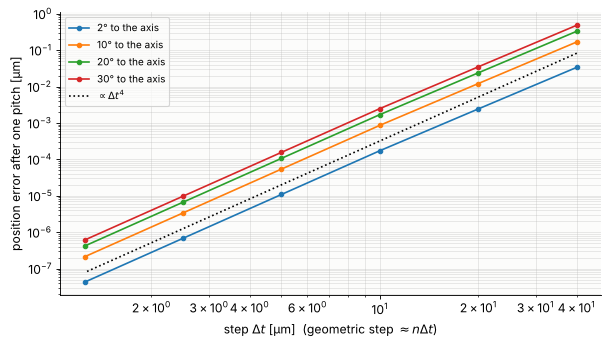

In [2]:
n0, P0 = 1.6, 400.0                      # index on the axis, paraxial pitch [µm]
g = 2*np.pi/P0
par = grin.ParabolicRod(n0, g, n_min=1.0)
angles = np.array([2, 10, 20, 30])*DEG    # in the glass
r0 = np.zeros((len(angles), 2))
d0 = np.c_[np.sin(angles), np.cos(angles)]
steps = np.array([40, 20, 10, 5, 2.5, 1.25])
err = []
for dt in steps:
    rays = grin.trace(par, r0, d0, dt, t_max=P0/n0)
    err.append(np.abs(rays.position - par.exact(r0, n0*d0, rays.t)).max(axis=1))
err = np.array(err)
fig, ax = plt.subplots(figsize=(7.5, 4.2), layout="constrained")
for j, a in enumerate(angles):
    ax.loglog(steps, err[:, j], "o-", ms=4, label=f"{a/DEG:.0f}° to the axis")
ax.loglog(steps, 2e-5*(steps/5)**4, "k:", label=r"$\propto \Delta t^4$")
ax.set_xlabel(r"step $\Delta t$ [µm]  (geometric step $\approx n\Delta t$)")
ax.set_ylabel("position error after one pitch [µm]")
ax.legend(fontsize=9); ax.grid(alpha=0.3, which="both")
print("order between the two smallest steps:", np.round(np.log2(err[-2]/err[-1]), 2))

## 2. GRIN rods: pitch, self-imaging and the perfect profile

A GRIN rod lens images through its own index profile: rays from a point on
the front face meet again on the axis after half a pitch $P/2$ (an
inverted image of the face), and after a full pitch the image is upright;
a parallel bundle is focused at $P/4$.

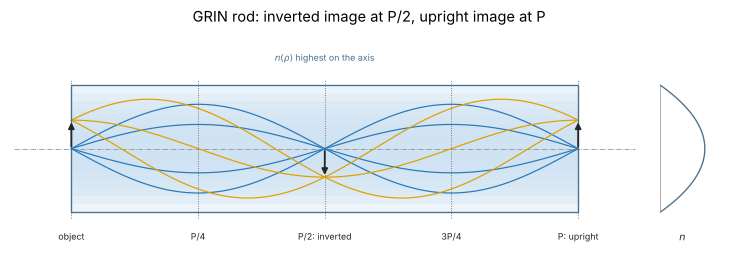

In [3]:
fig, ax = plt.subplots(figsize=(12, 3.6))
sketch.grin_rod_imaging(ax, title="GRIN rod: inverted image at P/2, upright image at P")
plt.tight_layout()

With the parabolic profile that holds only near the axis: the exact pitch
of a ray is $P(\theta) = 2\pi\beta/(n_0 g) = P_0\cos\theta$ (for a ray from
the axis), so steeper rays come back sooner and the image of a point is
blurred along the axis, a spherical aberration of the rod. The profile
$n = n_0\,\mathrm{sech}(g\rho)$ removes it exactly for meridional rays: the
solution
$$\sinh(gx) = \sinh(gx_0)\cos(gz) + \cosh(gx_0)\,x'_0\sin(gz)$$
has the period $2\pi/g$ for every start height and slope (Mikaelian). The
two profiles agree to second order in $\rho$, and their rays from the axis
agree in the paraxial limit. Below, a fan from an axial point (up to 32°
in the glass, NA 0.85), traced with `grin.trace()` and drawn against the
closed form paths (dashed).

parabolic: max |traced - P0 cos(theta)| = 4.8e-07 µm
sech:      max |traced - P0|           = 4.5e-07 µm


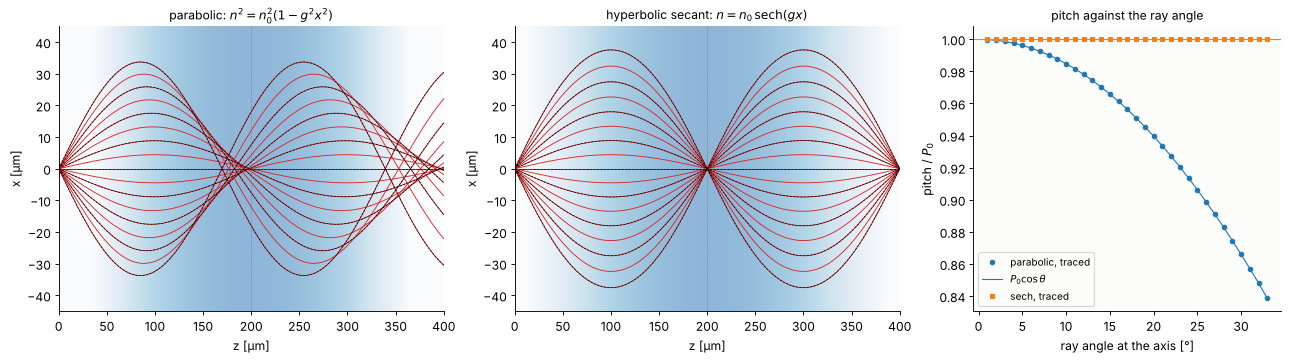

In [4]:
sech = grin.SechRod(n0, g)
fan = np.linspace(-32, 32, 17)*DEG
r0f = np.zeros((len(fan), 2))
d0f = np.c_[np.sin(fan), np.cos(fan)]
z_end = P0
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1, 1, 0.8]},
                         layout="constrained")
for ax, m, name in ((axes[0], par, "parabolic: $n^2 = n_0^2(1 - g^2x^2)$"),
                    (axes[1], sech, r"hyperbolic secant: $n = n_0\,\mathrm{sech}(gx)$")):
    rays = grin.trace(m, r0f, d0f, 1.0, stop=lambda r: r[:, 1] - z_end)
    xx = np.linspace(-45, 45, 200)
    ax.imshow(grin.index_map(m, xx, [0.0]).T.repeat(2, 0), extent=(0, z_end, -45, 45),
              cmap="Blues", vmin=1.3, vmax=1.7, aspect="auto", alpha=0.5)
    ax.plot(rays.path[:, :, 1], rays.path[:, :, 0], color="C3", lw=0.8)
    zz = np.linspace(0, z_end, 300)
    for a in fan[::2]:
        if m is par:
            x_ex = par.exact(np.zeros(2), n0*np.array([np.sin(a), np.cos(a)]), zz/(n0*np.cos(a)))[:, 0]
        else:
            x_ex = sech.exact_meridional(0.0, np.tan(a), zz)
        ax.plot(zz, x_ex, "k--", lw=0.6)
    ax.axvline(P0/2, color="0.4", lw=0.6, ls=":")
    ax.set_xlabel("z [µm]"); ax.set_ylabel("x [µm]"); ax.set_title(name, fontsize=11)
    ax.set_ylim(-45, 45)
# pitch against the launch angle: the first two axis crossings
th = np.linspace(1, 33, 33)*DEG
pitch = {}
for m in (par, sech):
    eps = 1e-9
    half = grin.trace(m, np.c_[np.full(len(th), eps), 0*th], np.c_[np.sin(th), np.cos(th)], 1.0,
                      stop=lambda r: r[:, 0])
    pitch[m] = 2*half.position[:, 1]
axes[2].plot(th/DEG, pitch[par]/P0, "o", ms=4, color="C0", label="parabolic, traced")
axes[2].plot(th/DEG, par.pitch(n0*np.cos(th))/P0, "-", color="C0", lw=1, label=r"$P_0\cos\theta$")
axes[2].plot(th/DEG, pitch[sech]/P0, "s", ms=4, color="C1", label="sech, traced")
axes[2].axhline(1, color="C1", lw=1)
axes[2].set_xlabel("ray angle at the axis [°]"); axes[2].set_ylabel("pitch / $P_0$")
axes[2].legend(fontsize=9); axes[2].set_title("pitch against the ray angle", fontsize=11)
print("parabolic: max |traced - P0 cos(theta)| = {:.1e} µm".format(
    np.abs(pitch[par] - par.pitch(n0*np.cos(th))).max()))
print("sech:      max |traced - P0|           = {:.1e} µm".format(np.abs(pitch[sech] - P0).max()))

The traced rays lie on the closed form paths, and the traced pitches on
$P_0\cos\theta$ and on $P_0$. At 30° the parabolic rod's pitch is 13 %
short: the axial image of a point is smeared over $P_0(1 - \cos\theta_{max})/2$,
26 µm for this fan.

### Waves in the two rods

The WPM propagates a narrow Gaussian (waist 0.6 µm at $\lambda$ = 0.8 µm,
about ±15° in the glass) through both rods over one pitch. The window is
±40 µm with an absorbing edge, 512 points; one run takes about 10 s. The rays
of the same angular range are drawn on top.

two WPM runs: 13 s
parabolic: brightest axial point near P/2 at z = 195 µm, peak at P/2 = 0.57, at P = 0.45 of the input
sech     : brightest axial point near P/2 at z = 200 µm, peak at P/2 = 0.98, at P = 0.98 of the input


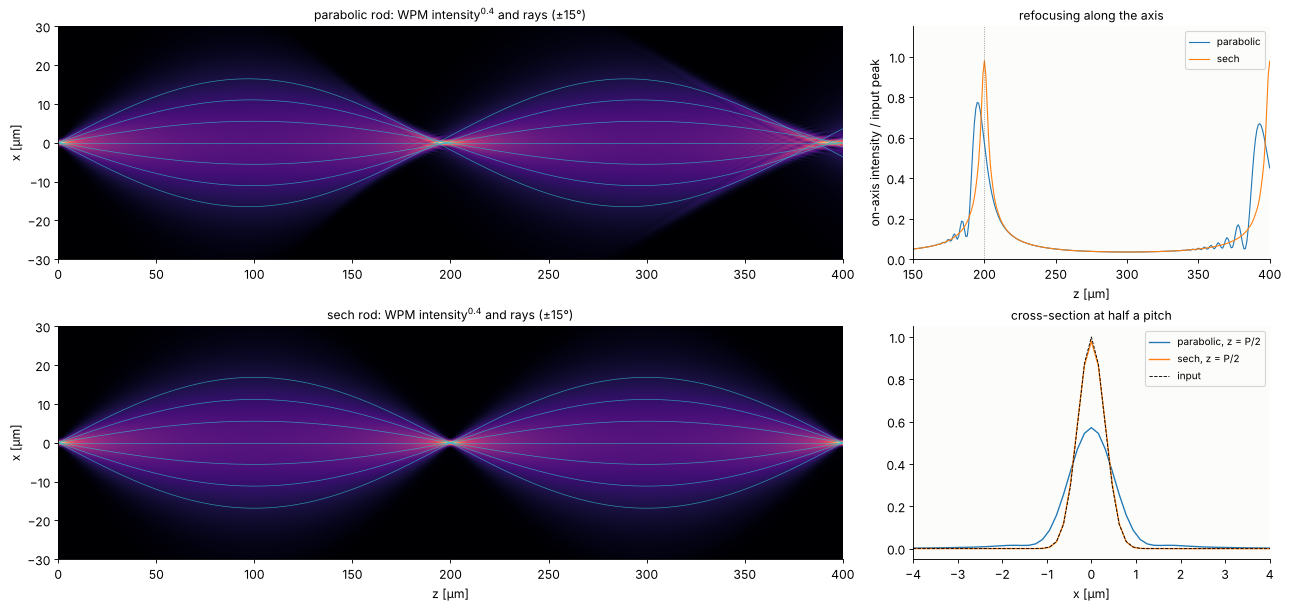

In [5]:
WL = 0.8
xw = grid1d(-40, 40, 512)
zw = np.arange(0, P0 + 0.01, 1.0)
absorb = lambda X: 1j*0.02*np.clip((np.abs(X) - 30)/10, 0, 1)**2


def wpm_rod(m, u0):
    n_func = lambda X, Y, z: m.n(np.stack([X, 0*X], axis=-1)) + absorb(X)
    return wpm_propagate_z(n_func, u0, xw, None, zw, WL)


u_point = np.exp(-xw**2/0.6**2)
t0 = time.time()
U_rod = {m: wpm_rod(m, u_point) for m in (par, sech)}
print("two WPM runs: {:.0f} s".format(time.time() - t0))
fan_w = np.linspace(-15, 15, 7)*DEG
fig = plt.figure(figsize=(16, 7.5), layout="constrained")
gs = fig.add_gridspec(2, 2, width_ratios=[2.2, 1])
for row, (m, name) in enumerate(((par, "parabolic"), (sech, "sech"))):
    ax = fig.add_subplot(gs[row, 0])
    I = np.abs(U_rod[m])**2
    show_intensity(ax, I, zw, xw, gamma=0.4)
    rays = grin.trace(m, np.zeros((len(fan_w), 2)), np.c_[np.sin(fan_w), np.cos(fan_w)], 1.0,
                      stop=lambda r: r[:, 1] - P0)
    ax.plot(rays.path[:, :, 1], rays.path[:, :, 0], color=RAY, lw=0.6, alpha=0.8)
    ax.set_ylim(-30, 30); ax.set_ylabel("x [µm]")
    ax.set_title(f"{name} rod: WPM intensity$^{{0.4}}$ and rays (±15°)", fontsize=11)
    if row == 1:
        ax.set_xlabel("z [µm]")
ax = fig.add_subplot(gs[0, 1])
for m, name, c in ((par, "parabolic", "C0"), (sech, "sech", "C1")):
    I = np.abs(U_rod[m])**2
    Ia = I[:, len(xw)//2]
    ax.plot(zw, Ia/I[0].max(), color=c, lw=1, label=name)
ax.axvline(P0/2, color="0.4", lw=0.6, ls=":"); ax.axvline(P0, color="0.4", lw=0.6, ls=":")
ax.set_xlim(150, P0); ax.set_ylim(0, 1.15); ax.set_xlabel("z [µm]")
ax.set_ylabel("on-axis intensity / input peak"); ax.legend(fontsize=9)
ax.set_title("refocusing along the axis", fontsize=11)
ax = fig.add_subplot(gs[1, 1])
i_half = np.argmin(np.abs(zw - P0/2))
for m, name, c in ((par, "parabolic", "C0"), (sech, "sech", "C1")):
    I = np.abs(U_rod[m])**2
    ax.plot(xw, I[i_half]/I[0].max(), color=c, lw=1.2, label=f"{name}, z = P/2")
ax.plot(xw, np.abs(u_point)**2, "k--", lw=0.8, label="input")
ax.set_xlim(-4, 4); ax.set_xlabel("x [µm]"); ax.legend(fontsize=9)
ax.set_title("cross-section at half a pitch", fontsize=11)
for m, name in ((par, "parabolic"), (sech, "sech")):
    I = np.abs(U_rod[m])**2
    Ia = I[:, len(xw)//2]
    k = np.argmax(np.where(zw > 150, Ia, 0)[:len(zw)//2 + 40])
    print(f"{name:9s}: brightest axial point near P/2 at z = {zw[k]:.0f} µm, "
          f"peak at P/2 = {I[i_half].max()/I[0].max():.2f}, at P = {I[-1].max()/I[0].max():.2f} of the input")

The waves follow the rays. In the parabolic rod the steep rays cross the
axis before $P/2$, the focus moves forward by a few µm, is wider and
has lost about half its peak; after a full pitch it is worse. The sech rod
brings the point back to almost its input peak at exactly $P/2$ and $P$.
(The sech profile is perfect for meridional rays only; skew rays in a
round rod still spiral with slightly different periods. A cylindrical,
slab-like rod as here has only meridional rays.)

### Self-imaging of an object

An object in contact with the front face, here three slits of different
widths lit by a plane wave, is imaged inverted at $P/2$ and upright at $P$;
at $P/4$ the plane wave is focused to a spot (the Fourier transform of the
object).

correlation with the object: inverted at P/2 0.968, upright at P 0.980


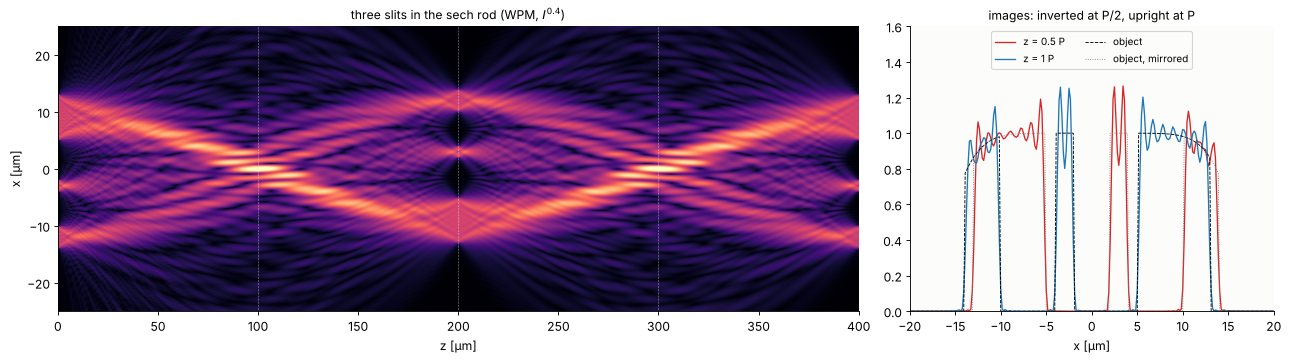

In [6]:
obj = ((xw > -14) & (xw < -10)) | ((xw > -4) & (xw < -2)) | ((xw > 5) & (xw < 13))
obj = obj*np.exp(-(xw/18)**8)
U_obj = wpm_rod(sech, obj.astype(complex))
I = np.abs(U_obj)**2
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw={"width_ratios": [2.2, 1]},
                         layout="constrained")
show_intensity(axes[0], I, zw, xw, gamma=0.4, vmax=np.abs(obj).max()**2*4)
for q in (0.25, 0.5, 0.75, 1.0):
    axes[0].axvline(q*P0, color="w", lw=0.5, ls=":")
axes[0].set_ylim(-25, 25); axes[0].set_xlabel("z [µm]"); axes[0].set_ylabel("x [µm]")
axes[0].set_title("three slits in the sech rod (WPM, $I^{0.4}$)", fontsize=11)
for q, c, ls in ((0.5, "C3", "-"), (1.0, "C0", "-")):
    k = np.argmin(np.abs(zw - q*P0))
    axes[1].plot(xw, I[k], color=c, lw=1.2, ls=ls, label=f"z = {q:g} P")
axes[1].plot(xw, np.abs(obj)**2, "k--", lw=0.8, label="object")
axes[1].plot(-xw, np.abs(obj)**2, ":", color="0.5", lw=0.8, label="object, mirrored")
axes[1].set_xlim(-20, 20); axes[1].set_ylim(0, 1.6); axes[1].set_xlabel("x [µm]")
axes[1].legend(fontsize=9, loc="upper center", ncol=2)
axes[1].set_title("images: inverted at P/2, upright at P", fontsize=11)
k_half = np.argmin(np.abs(zw - P0/2))
c_half = np.corrcoef(I[k_half], np.abs(obj[::-1])**2)[0, 1]
c_full = np.corrcoef(I[-1], np.abs(obj)**2)[0, 1]
print(f"correlation with the object: inverted at P/2 {c_half:.3f}, upright at P {c_full:.3f}")

The images are sharp copies with soft edges, the rod passes only the
angles it guides (NA $= \sqrt{n_0^2 - n(30\,\mu m)^2}$). A GRIN lens of a
quarter pitch is the classic fibre collimator; endoscopes relay images
through several half pitch rods.

## 3. The Luneburg lens

In a sphere (or, here, a cylinder) with $n^2 = 2 - (r/R)^2$ and $n = 1$
outside, the index is continuous at the surface, so nothing is reflected
there, and $\tfrac12\nabla n^2 = -\mathbf r/R^2$: inside, rays are
harmonic oscillations about the centre, ellipses
$\mathbf r(t) = \mathbf r_0\cos(t/R) + R\,\mathbf T_0\sin(t/R)$. A ray that
enters parallel to $x$ has $\mathbf T_0 = \hat{\mathbf x}$ (since $n = 1$
at the surface) and reaches $\mathbf r = R\hat{\mathbf x}$ at
$t = \pi R/2$, whatever its height: a parallel bundle from any direction
is focused on the opposite point of the surface. Luneburg lenses are used
as microwave antennas and radar reflectors, made of shells of foam.

   0 deg: max distance of the exits from the focus 5.8e-12, t at the exit 7.853982 .. 7.853982 (pi R/2 = 7.853982), optical path spread 1.5e-11
  35 deg: max distance of the exits from the focus 4.8e-12, t at the exit 7.853982 .. 7.853982 (pi R/2 = 7.853982), optical path spread 1.5e-11


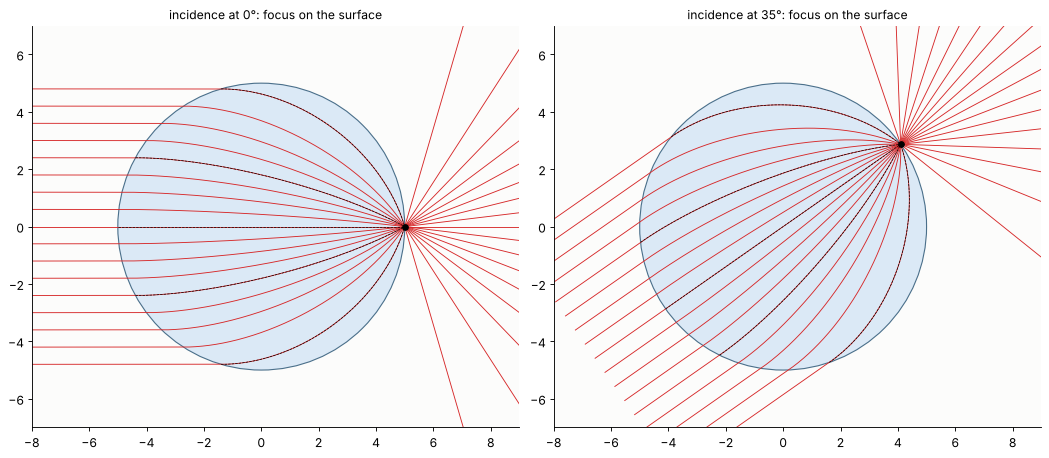

In [7]:
R = 5.0                                   # in wavelengths
lune = grin.Luneburg(R)
b = np.linspace(-0.96, 0.96, 17)*R
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), layout="constrained")
for ax, inc in zip(axes, (0.0, 35.0)):
    u = np.array([np.cos(inc*DEG), np.sin(inc*DEG)])
    v = np.array([-u[1], u[0]])
    start = -1.6*R*u + b[:, None]*v
    # straight to the surface, then through the lens, then straight again
    s_in = -(start @ u) - np.sqrt(R**2 - b**2)
    entry = (start + s_in[:, None]*u)*(1 - 1e-12)          # just inside the surface
    rays = grin.trace(lune, entry, np.tile(u, (len(b), 1)), 0.02,
                      stop=lambda r: np.sum(r**2, axis=1) - R**2)
    focus = R*u
    ax.add_patch(plt.Circle((0, 0), R, facecolor="#dbe9f6", edgecolor="#4a6f8a"))
    for j in range(len(b)):
        p = rays.path[:, j]
        p = p[np.r_[True, np.any(np.diff(p, axis=0) != 0, axis=1)]]
        out = p[-1] + np.outer([0, 1.5*R], rays.direction[j])
        ax.plot(np.r_[start[j, 0], p[:, 0], out[:, 0]], np.r_[start[j, 1], p[:, 1], out[:, 1]],
                color="C3", lw=0.8)
    tt = np.linspace(0, np.pi*R/2, 100)
    for j in range(0, len(b), 4):
        e = lune.exact(entry[j], u, tt)
        ax.plot(e[:, 0], e[:, 1], "k--", lw=0.6)
    ax.plot(*focus, "o", color="k", ms=5)
    ax.set_aspect("equal"); ax.set_xlim(-1.6*R, 1.8*R); ax.set_ylim(-1.4*R, 1.4*R)
    ax.set_title(f"incidence at {inc:.0f}°: focus on the surface", fontsize=11)
    print(f"{inc:4.0f} deg: max distance of the exits from the focus {np.abs(rays.position - focus).max():.1e}, "
          f"t at the exit {rays.t.min():.6f} .. {rays.t.max():.6f} (pi R/2 = {np.pi*R/2:.6f}), "
          f"optical path spread {np.ptp(rays.opl + s_in):.1e}")

All rays leave through the focus at $t = \pi R/2$, and the optical paths
from a plane in front of the lens to the focus are equal to rounding, as
Fermat's principle demands of a perfect focus.

### Waves: FDFD

The Ez field of a plane wave on a lens of radius 5 λ, with the
permittivity $n^2(x, y)$ averaged over each cell of a grid of 25 cells per
vacuum wavelength (a small subclass of `fdfd.Simulation` replaces the
shapes by the function). The total field region of the plane wave source
encloses the lens, in vacuum.

two FDFD solves (140625 unknowns each): 3 s
brightest point on the axis at x = 4.90 λ (surface at 5 λ), |Ez|² = 27.3, FWHM across 0.36 λ


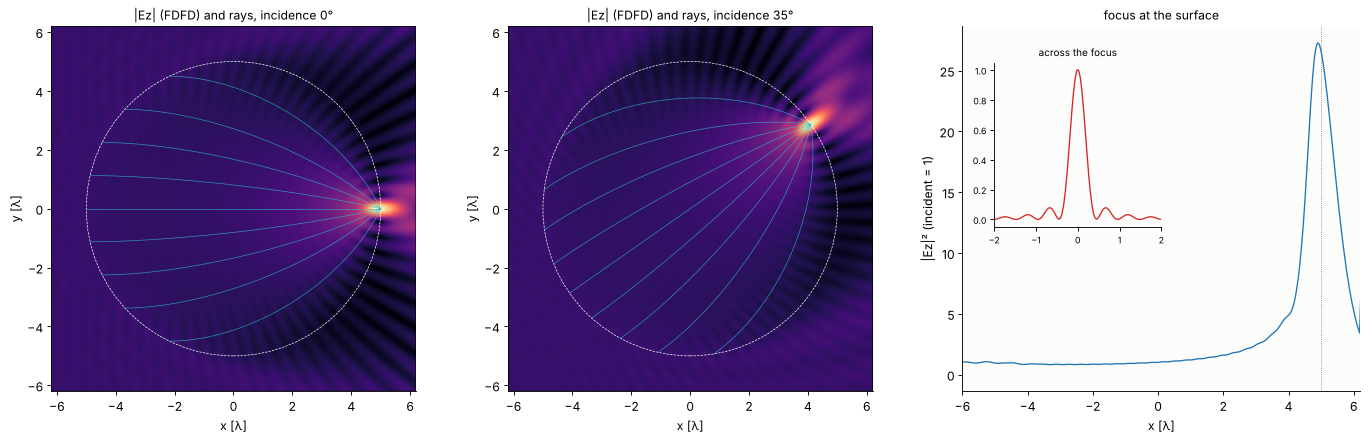

In [8]:
grid_l = fdtd.Grid((15.0, 15.0), 0.04)
sim_l = GradedSimulation(grid_l, lambda X, Y: lune.n2(np.stack([X, Y], axis=-1)))
box = ((-6.2, 6.2), (-6.2, 6.2))
t0 = time.time()
sols = {inc: sim_l.solve(1.0, fdfd.PlaneWave(inc*DEG, box)) for inc in (0.0, 35.0)}
print("two FDFD solves ({} unknowns each): {:.0f} s".format(np.prod(grid_l.shape), time.time() - t0))
xl, yl = sols[0.0].coords["Ez"]
inbox = (np.abs(xl) < 6.2)[:, None] & (np.abs(yl) < 6.2)[None, :]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), gridspec_kw={"width_ratios": [1, 1, 0.9]},
                         layout="constrained")
for ax, inc in zip(axes, (0.0, 35.0)):
    u = sols[inc].main
    I = np.where(inbox, np.abs(u)**2, 0)
    ax.imshow(np.sqrt(I/I.max()).T, extent=(xl[0], xl[-1], yl[0], yl[-1]), cmap="magma")
    ax.add_patch(plt.Circle((0, 0), R, fill=False, ec="w", lw=0.6, ls="--"))
    d = np.array([np.cos(inc*DEG), np.sin(inc*DEG)])
    v = np.array([-d[1], d[0]])
    bb = np.linspace(-0.9, 0.9, 9)*R
    entry = -np.sqrt(R**2 - bb**2)[:, None]*(1 - 1e-12)*d + bb[:, None]*v
    rays = grin.trace(lune, entry, np.tile(d, (len(bb), 1)), 0.02,
                      stop=lambda r: np.sum(r**2, axis=1) - R**2)
    ax.plot(rays.path[:, :, 0], rays.path[:, :, 1], color=RAY, lw=0.6, alpha=0.8)
    ax.set_xlim(-6.2, 6.2); ax.set_ylim(-6.2, 6.2); ax.set_aspect("equal")
    ax.set_title(f"|Ez| (FDFD) and rays, incidence {inc:.0f}°", fontsize=11)
    ax.set_xlabel("x [λ]"); ax.set_ylabel("y [λ]")
u0 = sols[0.0].main
j0 = np.argmin(np.abs(yl))
I_ax = np.abs(u0[:, j0])**2
axes[2].plot(xl, I_ax, color="C0", lw=1.2, label="along the axis y = 0")
i_f = np.argmax(np.where(inbox[:, j0], I_ax, 0))
axes[2].axvline(R, color="0.4", lw=0.7, ls=":")
axes[2].set_xlim(-6, 6.2); axes[2].set_xlabel("x [λ]"); axes[2].set_ylabel("|Ez|² (incident = 1)")
ax2 = axes[2].inset_axes([0.08, 0.45, 0.42, 0.45])
I_tr = np.abs(u0[i_f])**2
ax2.plot(yl, I_tr/I_tr.max(), color="C3", lw=1.2)
ax2.set_xlim(-2, 2); ax2.set_title("across the focus", fontsize=9); ax2.tick_params(labelsize=8)
half = yl[I_tr >= I_tr.max()/2]
axes[2].set_title("focus at the surface", fontsize=11)
print(f"brightest point on the axis at x = {xl[i_f]:.2f} λ (surface at {R:.0f} λ), "
      f"|Ez|² = {I_ax[i_f]:.1f}, FWHM across {half.max() - half.min():.2f} λ")

The waves converge where the rays do. The brightest point lies a few tenths
of a wavelength inside the surface: the focus is cut by the edge of the
lens, and the light continues as a diverging wave in vacuum. Its width
across (FWHM 0.36 λ) is that of a focus at $n \approx 1$ fed from a half
space of angles: the Luneburg lens works at its diffraction limit for every
direction, without a single tilted surface.

## 4. Maxwell's fish-eye

Maxwell (1854) found the medium $n = n_0/(1 + (r/R)^2)$ as an exercise:
all its rays are circles, and all rays from a point $\mathbf r_0$ meet again
in $\mathbf r_0' = -\mathbf r_0 R^2/|\mathbf r_0|^2$. The reason is a
projection: the fish-eye is the stereographic projection of a sphere of
radius $R$ (for $n_0 = 2$), and rays are the projected great circles. Every
great circle through a point also passes through its antipode, which
projects to $\mathbf r_0'$. All of them have the same length, $\pi R$, so
the optical paths from $\mathbf r_0$ to its image are equal: a perfect
image for rays.

distance of the traced ends from the image: 7.9e-09
distance of the path from the analytic circles: 5.3e-09
optical paths to the image: 3.141593 ... 3.141593 (pi R = 3.141593)


mirror: max distance of the ends from -r0 6.6e-12, optical paths 3.141593 ... 3.141593


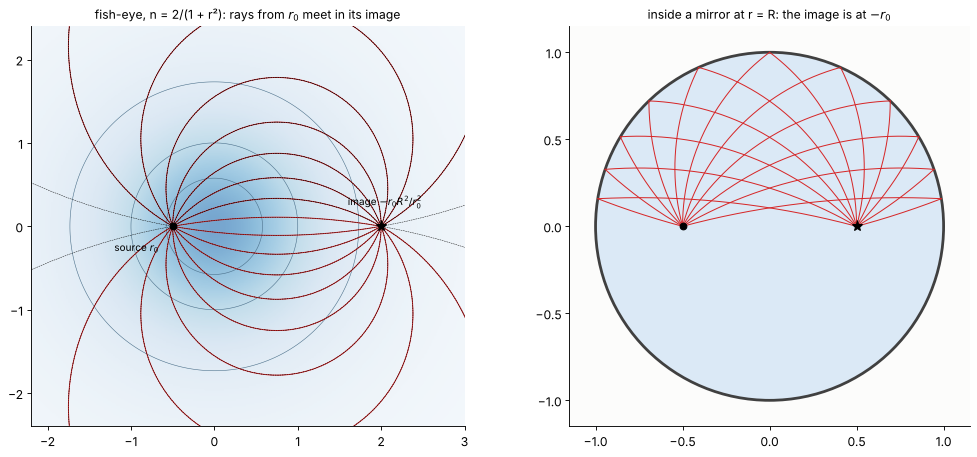

In [9]:
eye = grin.MaxwellFishEye(1.0)
p0 = np.array([-0.5, 0.0])
img = eye.image(p0)
a = np.r_[np.linspace(10, 150, 8), -np.linspace(10, 150, 8)]*DEG
d = np.c_[np.cos(a), np.sin(a)]
side = np.sign(d[:, 1])
rays = grin.trace(eye, np.tile(p0, (len(a), 1)), d, 0.002, stop=lambda r: side*r[:, 1] + 1e-12)
c, rad = eye.circle(np.tile(p0, (len(a), 1)), d)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), layout="constrained")
xx = np.linspace(-3, 3, 300)
N = grin.index_map(eye, xx, xx)
axes[0].imshow(N.T, extent=(-3, 3, -3, 3), cmap="Blues", vmin=0, vmax=2.6, alpha=0.6)
axes[0].contour(xx, xx, N.T, levels=[0.5, 1.0, 1.5], colors="#4a6f8a", linewidths=0.5)
for j in range(len(a)):
    axes[0].plot(rays.path[:, j, 0], rays.path[:, j, 1], color="C3", lw=0.9)
    phi = np.linspace(0, 2*np.pi, 200)
    axes[0].plot(c[j, 0] + rad[j]*np.cos(phi), c[j, 1] + rad[j]*np.sin(phi), "k--", lw=0.4)
axes[0].plot(*p0, "o", color="k"); axes[0].plot(*img, "*", color="k", ms=10)
axes[0].annotate("source $r_0$", p0, xytext=(-1.2, -0.3), fontsize=9)
axes[0].annotate("image $-r_0R^2/r_0^2$", img, xytext=(1.6, 0.25), fontsize=9)
axes[0].set_xlim(-2.2, 3); axes[0].set_ylim(-2.4, 2.4); axes[0].set_aspect("equal")
axes[0].set_title("fish-eye, n = 2/(1 + r²): rays from $r_0$ meet in its image", fontsize=11)
print("distance of the traced ends from the image: {:.1e}".format(np.abs(rays.position - img).max()))
print("distance of the path from the analytic circles: {:.1e}".format(
    np.abs(np.linalg.norm(rays.path - c, axis=-1) - rad).max()))
print("optical paths to the image: {:.6f} ... {:.6f} (pi R = {:.6f})".format(
    rays.opl.min(), rays.opl.max(), np.pi))

# with a mirror at r = R: the image of r0 is -r0
side = np.sign(d[:, 1])
p_end = []
fan2 = np.linspace(15, 165, 11)*DEG
d2 = np.c_[np.cos(fan2), np.sin(fan2)]
axes[1].add_patch(plt.Circle((0, 0), 1, facecolor="#dbe9f6", edgecolor="0.25", lw=2.5))
for dd in d2:
    pos, dirn, opl = p0.copy(), dd.copy(), 0.0
    for leg in range(2):
        last = leg == 1
        stop = (lambda r: r[:, 1] + 1e-12) if last else (lambda r: np.sum(r**2, axis=1) - 1.0)
        rr = grin.trace(eye, pos, dirn, 0.002, stop=stop)
        axes[1].plot(rr.path[:, 0, 0], rr.path[:, 0, 1], color="C3", lw=0.9)
        pos, opl = rr.position[0], opl + rr.opl[0]
        nrm = pos/np.linalg.norm(pos)
        dirn = rr.direction[0] - 2*(rr.direction[0] @ nrm)*nrm    # reflect at the mirror
    p_end.append((pos, opl))
p_end = np.array([np.r_[p, o] for p, o in p_end])
axes[1].plot(*p0, "o", color="k"); axes[1].plot(-p0[0], 0, "*", color="k", ms=10)
axes[1].set_xlim(-1.15, 1.15); axes[1].set_ylim(-1.15, 1.15); axes[1].set_aspect("equal")
axes[1].set_title("inside a mirror at r = R: the image is at $-r_0$", fontsize=11)
print("mirror: max distance of the ends from -r0 {:.1e}, optical paths {:.6f} ... {:.6f}".format(
    np.abs(p_end[:, :2] + p0).max(), p_end[:, 2].min(), p_end[:, 2].max()))

Traced rays lie on the analytic circles to $10^{-8}$, end in the image
point, and all have the optical path $\pi R$ (half a great circle).
Leonhardt (2009) put a mirror around the unit circle: it maps the outer
image $-\mathbf r_0/|\mathbf r_0|^2$ back to $-\mathbf r_0$, and the device
images the inside onto itself (right).

### Waves in the mirrored fish-eye

Because the 2D Helmholtz equation is conformally invariant, the projection
carries over to waves: $\nabla^2 u + k_0^2n^2u = -\delta$ in the plane is
$\Delta_S u + k_0^2u = -\delta_S$ on the sphere of radius $R$. Its Green's
function depends only on the angle $\gamma$ between the two points on the
sphere,
$$G = -\frac{P_\nu(-\cos\gamma)}{4\sin\pi\nu}, \qquad \nu(\nu + 1) = (k_0R)^2,$$
with the Legendre function $P_\nu$; the mirror at the equator ($u = 0$) adds
a negative image source at $\mathbf r_0R^2/|\mathbf r_0|^2$. The FDFD
solution for a line source in a fish-eye of radius $R = 4\lambda$ inside a
perfect conductor (a permittivity of $-10^4$ outside), on 50 cells per
vacuum wavelength, against this formula ($u = ik_0G$ for the unit current
of `fdfd.PointSource`):

FDFD solve (184900 unknowns): 2.2 s


nu = 24.6377; rms deviation FDFD - exact inside the mirror: 6.0 %
image spot: FWHM of |Ez|^2 across = 0.20 λ; local wavelength λ/n = 0.62 λ


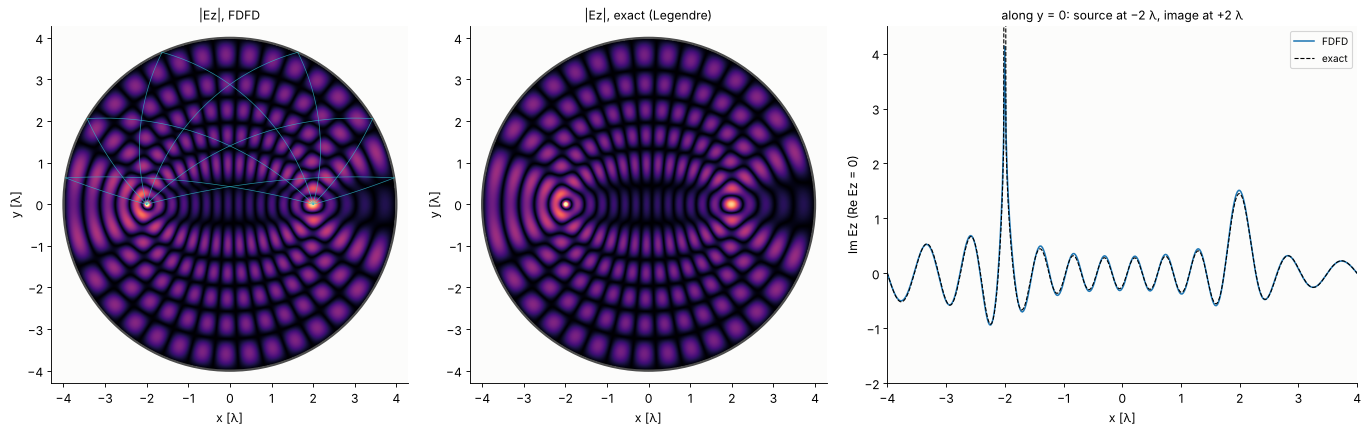

In [10]:
Rf = 4.0
fish = grin.MaxwellFishEye(Rf)
k0 = 2*np.pi
eps_f = lambda X, Y: np.where(X**2 + Y**2 < Rf**2, fish.n2(np.stack([X, Y], axis=-1)), -1e4)
sim_f = GradedSimulation(fdtd.Grid((8.6, 8.6), 0.02), eps_f, boundaries=("pec", "pec"))
xs_f, ys_f = sim_f.coords("Ez")
src = np.array([xs_f[np.argmin(np.abs(xs_f + 2.0))], 0.0])       # on a node, 2 λ left of the centre
t0 = time.time()
sol_f = sim_f.solve(1.0, fdfd.PointSource(tuple(src)))
print("FDFD solve ({} unknowns): {:.1f} s".format(np.prod(sim_f.grid.shape), time.time() - t0))
nu = -0.5 + np.sqrt(0.25 + (k0*Rf)**2)


def on_sphere(X, Y):
    r2 = X**2 + Y**2
    return np.stack([2*Rf*X, 2*Rf*Y, r2 - Rf**2], axis=-1)/(r2 + Rf**2)[..., None]


def green(X, Y, p):
    cg = np.clip(np.sum(on_sphere(X, Y)*on_sphere(*p), axis=-1), -1, 1)
    return -lpmv(0, nu, -cg)/(4*np.sin(np.pi*nu))


X, Y = np.meshgrid(xs_f, ys_f, indexing="ij")
u_ex = 1j*k0*(green(X, Y, src) - green(X, Y, src*Rf**2/np.sum(src**2)))
u_fd = sol_f.main
inside = (X**2 + Y**2 < (0.97*Rf)**2) & (np.hypot(X - src[0], Y - src[1]) > 0.3)
rel = np.sqrt(np.mean(np.abs(u_fd - u_ex)[inside]**2)/np.mean(np.abs(u_ex)[inside]**2))
print(f"nu = {nu:.4f}; rms deviation FDFD - exact inside the mirror: {100*rel:.1f} %")
fig, axes = plt.subplots(1, 3, figsize=(17, 5.3), gridspec_kw={"width_ratios": [1, 1, 1.25]},
                         layout="constrained")
mask = X**2 + Y**2 < Rf**2
for ax, u, name in ((axes[0], u_fd, "FDFD"), (axes[1], u_ex, "exact (Legendre)")):
    ax.imshow(np.where(mask, np.abs(u), np.nan).T, extent=(xs_f[0], xs_f[-1], ys_f[0], ys_f[-1]),
              cmap="magma", vmax=1.6)
    ax.add_patch(plt.Circle((0, 0), Rf, fill=False, ec="0.3", lw=2))
    ax.set_aspect("equal"); ax.set_title(f"|Ez|, {name}", fontsize=11)
    ax.set_xlabel("x [λ]"); ax.set_ylabel("y [λ]")
for dd in d2[::2]:
    pos, dirn = src/Rf, dd.copy()
    for leg in range(2):
        stop = (lambda r: r[:, 1] + 1e-12) if leg else (lambda r: np.sum(r**2, axis=1) - 1.0)
        rr = grin.trace(eye, pos, dirn, 0.004, stop=stop)
        axes[0].plot(Rf*rr.path[:, 0, 0], Rf*rr.path[:, 0, 1], color=RAY, lw=0.6, alpha=0.8)
        pos = rr.position[0]
        nrm = pos/np.linalg.norm(pos)
        dirn = rr.direction[0] - 2*(rr.direction[0] @ nrm)*nrm
j0 = np.argmin(np.abs(ys_f))
axes[2].plot(xs_f, np.imag(u_fd[:, j0]), color="C0", lw=1.4, label="FDFD")
axes[2].plot(xs_f, np.imag(u_ex[:, j0]), "--", color="k", lw=1, label="exact")
axes[2].set_ylim(-2, 4.5); axes[2].set_xlim(-Rf, Rf)
axes[2].set_xlabel("x [λ]"); axes[2].set_ylabel("Im Ez (Re Ez = 0)"); axes[2].legend(fontsize=9)
axes[2].set_title("along y = 0: source at −2 λ, image at +2 λ", fontsize=11)
i_img = np.argmin(np.abs(xs_f + src[0]))
prof = np.abs(u_ex[i_img])
w_img = ys_f[prof >= prof.max()/np.sqrt(2)]
print("image spot: FWHM of |Ez|^2 across = {:.2f} λ; local wavelength λ/n = {:.2f} λ".format(
    w_img.max() - w_img.min(), 1/fish.n(np.array([src[0], 0.0]))))

FDFD and the exact field agree within 6 % rms (the rest is the grid
dispersion over some 16 local wavelengths and the staircase of the
mirror). The
standing wave has a bright spot at the image point, but unlike the source
it is not singular: without anything that absorbs the light at the image,
the field there is a superposition of the converging and the diverging
wave, a standing $J_0$-like spot about a third of the local wavelength
wide (FWHM of $|E_z|^2$ 0.20 λ at $\lambda/n$ = 0.62 λ), the diffraction
limit of a spot fed from all directions. Whether a "drain" at the image makes the fish-eye a perfect lens for
waves too was a lively debate after Leonhardt's proposal (Blaikie,
Merlin, Leonhardt and Philbin 2010–2011).

The closed fish-eye is also a resonator with a remarkably simple
spectrum: the modes are spherical harmonics on the sphere, with
$(k_0R)^2 = \ell(\ell + 1)$, and the mirror (u = 0 at the equator) keeps
those with $\ell + m$ odd, $\ell$-fold degenerate. The eigenvalue solver
of `fdfd` finds them:

In [11]:
t0 = time.time()
res = []
for l in (8, 9):
    wl_l = 2*np.pi*Rf/np.sqrt(l*(l + 1))
    res.append(sim_f.resonances(wl_l, n=l + 2, refine=0))
print("eigenvalue solves: {:.0f} s".format(time.time() - t0))
for l, rr in zip((8, 9), res):
    kR = np.sort([2*np.pi*Rf/r.wavelength for r in rr])
    print(f"l = {l}: exact k0 R = {np.sqrt(l*(l + 1)):.4f}, FDFD:", np.round(kR, 4))

eigenvalue solves: 20 s
l = 8: exact k0 R = 8.4853, FDFD: [7.4804 7.4805 8.4797 8.4797 8.4815 8.4815 8.482  8.482  8.4827 8.4827]
l = 9: exact k0 R = 9.4868, FDFD: [8.4827 8.4827 9.4807 9.4807 9.4829 9.4829 9.4836 9.4836 9.484  9.4844
 9.4844]


For $\ell$ = 8 and 9 the solver finds groups of eight and nine modes at
$\sqrt{\ell(\ell + 1)}$, within 0.07 % and split by less than $5\times10^{-4}$
by the grid and the staircase mirror (pairs are degenerate by the mirror
symmetry $y \to -y$); the other modes in each list belong to the
neighbouring $\ell$.

## 5. The mirage over a hot road

On a sunny day the road ahead looks wet: the sky is reflected in it,
and a car far ahead seems to stand in a puddle, with an inverted copy
below it. The air touching the asphalt is much hotter than the air above;
at constant pressure $n - 1 \propto 1/T$, so the index is lowest at the
ground and rays that run down at a grazing angle are bent back up. The
eye sees light from the sky, or from the car, coming from below the
horizon: an inferior mirage.

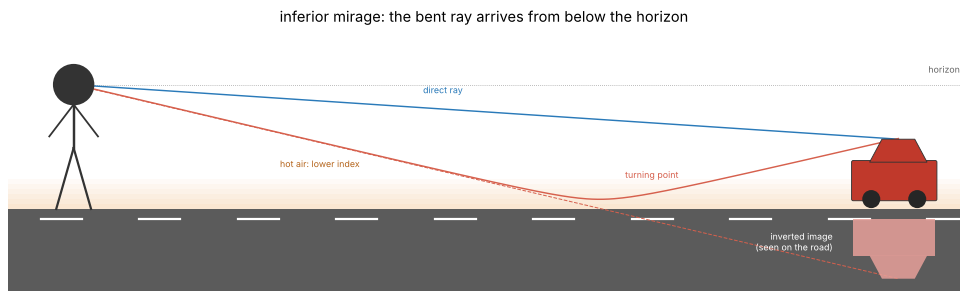

In [12]:
fig, ax = plt.subplots(figsize=(13, 3.8))
sketch.road_mirage(ax, title="inferior mirage: the bent ray arrives from below the horizon")
plt.tight_layout()

The index of air at 15 °C is $n_{15} - 1 = 2.78\times10^{-4}$ (Ciddor, 550 nm).
With the air at 30 °C and the asphalt at 60 °C, the temperature, and with
it $n^2$, approaches the air value nearly exponentially over a layer of
some centimetres; here $n^2 = n_\infty^2 - \delta\,e^{-y/h}$ with
$h$ = 5 cm and $\delta = n_\infty^2 - n_{ground}^2$. A ray stays above the
ground if $n\cos\alpha$ at the eye is larger than $n_{ground}$: only rays
within $\alpha_c \approx \sqrt{2\Delta n}$ below the horizon come back,
here 0.39°. Rays that leave the eye (1.6 m above the road) at slightly
steeper angles hit the asphalt; the eye sees the road there.

For this profile the path follows in closed form from the invariant
$\beta = n\cos\alpha$: with $c = n_\infty^2 - \beta^2$ and
$w = \sqrt{1 - \delta e^{-y/h}/c}$, the horizontal distance from the lowest
point at the height $y_t = h\ln(\delta/c)$ is
$x = 2\beta h\,\mathrm{artanh}(w)/\sqrt c$ (`ExponentialLayer.horizontal_distance()`).

n - 1: air 2.641e-04, at the road 2.403e-04; critical angle 0.395°


traced vs closed form heights: max deviation 4.8e-06 m


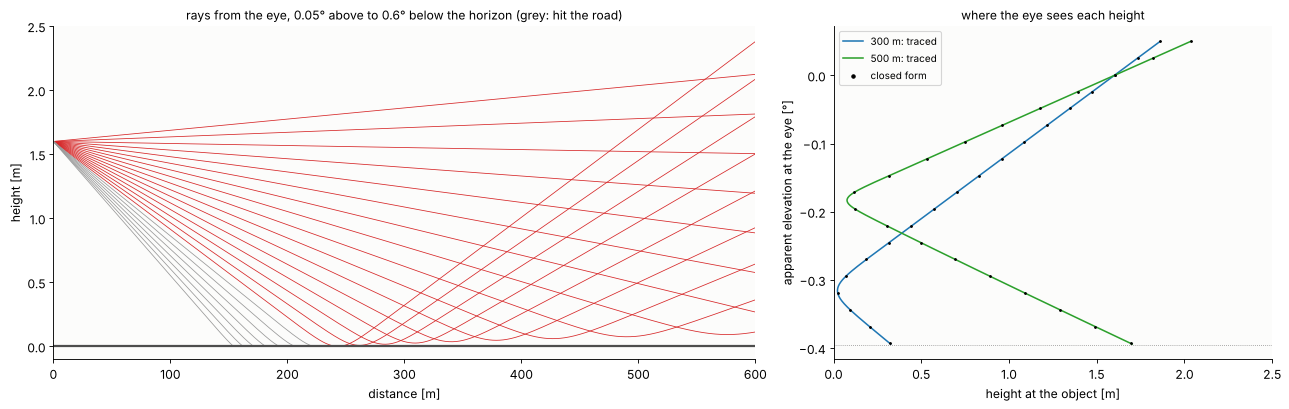

In [13]:
n15 = air_index(550.0)
n_of_T = lambda T: 1 + (n15 - 1)*288.15/(273.15 + T)
n_far, n_ground = n_of_T(30.0), n_of_T(60.0)
road = grin.ExponentialLayer(n_far, n_far**2 - n_ground**2, 0.05)
y_eye = 1.6
alpha_c = np.arccos(n_ground/road.n(np.array([0, y_eye])))
print(f"n - 1: air {n_far - 1:.3e}, at the road {n_ground - 1:.3e}; critical angle {alpha_c/DEG:.3f}°")

# a fan of rays from the eye; rays that reach the road end there
alpha = -np.linspace(-0.05, 0.60, 661)*DEG          # elevation, negative = below the horizon
fan_r = grin.trace(road, np.tile([0.0, y_eye], (len(alpha), 1)), np.c_[np.cos(alpha), np.sin(alpha)],
                   0.5, stop=lambda r: np.minimum(r[:, 1], 600.0 - r[:, 0]))
hits_road = fan_r.position[:, 1] < 1e-6


def exact_height(a, D):
    # height at the distance D of the ray leaving the eye at the elevation a (closed form),
    # nan if it hits the road
    b = road.n(np.array([0, y_eye]))*np.cos(a)
    H = road.horizontal_distance
    if a >= 0:          # rising from the start: past its (virtual) lowest point
        return brentq(lambda y: H(b, y) - (H(b, y_eye) + D), y_eye, 1e3)
    if b <= n_ground:
        return np.nan
    y_t = road.turning_height(b)
    x_t = H(b, y_eye)
    if D <= x_t:        # still on its way down
        return brentq(lambda y: H(b, y) - (x_t - D), y_t, y_eye)
    return brentq(lambda y: H(b, y) - (D - x_t), y_t, 1e3)


fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.6, 1]},
                         layout="constrained")
ax = axes[0]
for j in range(0, len(alpha), 30):
    p = fan_r.path[:, j]
    ax.plot(p[:, 0], p[:, 1], color="C3" if not hits_road[j] else "0.6", lw=0.7)
ax.axhline(0, color="0.3", lw=2)
ax.set_xlim(0, 600); ax.set_ylim(-0.1, 2.5)
ax.set_xlabel("distance [m]"); ax.set_ylabel("height [m]")
ax.set_title("rays from the eye, 0.05° above to 0.6° below the horizon (grey: hit the road)",
             fontsize=11)
# the image of a car 300 m and of a mast 500 m ahead
dev = []
for D, c in ((300.0, "C0"), (500.0, "C2")):
    y_D = np.array([np.interp(D, fan_r.path[:, j, 0], fan_r.path[:, j, 1]) if fan_r.path[-1, j, 0] >= D
                    else np.nan for j in range(len(alpha))])
    y_x = np.array([exact_height(a, D) for a in alpha])
    ok = np.isfinite(y_D) & np.isfinite(y_x)
    dev.append(np.abs(y_D - y_x)[ok].max())
    axes[1].plot(y_D, alpha/DEG, color=c, lw=1.4, label=f"{D:.0f} m: traced")
    axes[1].plot(y_x[::25], alpha[::25]/DEG, "k.", ms=3)
axes[1].plot([], [], "k.", label="closed form")
axes[1].set_xlim(0, 2.5); axes[1].set_xlabel("height at the object [m]")
axes[1].set_ylabel("apparent elevation at the eye [°]")
axes[1].axhline(-alpha_c/DEG, color="0.5", lw=0.7, ls=":")
axes[1].legend(fontsize=9); axes[1].set_title("where the eye sees each height", fontsize=11)
print("traced vs closed form heights: max deviation {:.1e} m".format(max(dev)))

The traced heights agree with the closed form to a few micrometres over
hundreds of metres. Each object height is seen twice: once directly (upright, the
upper branch) and once via the bent rays (lower branch, inverted: higher
points appear lower). The two branches meet at the lowest apparent
elevation that still reaches the object, the "vanishing line": everything
of the object below the fold height is hidden, while the parts above it
appear twice. Below the vanishing line the eye looks at the road. With
distance the fold moves up, so far objects lose their bases and float
above a "lake".

What the eye sees can be rendered directly by following each pixel's ray:
a red and white striped mast of 3 m at 200, 350 and 500 m, the sky
brightening towards the horizon, and the grey road.

Text(0, 0.5, 'apparent elevation [°]')

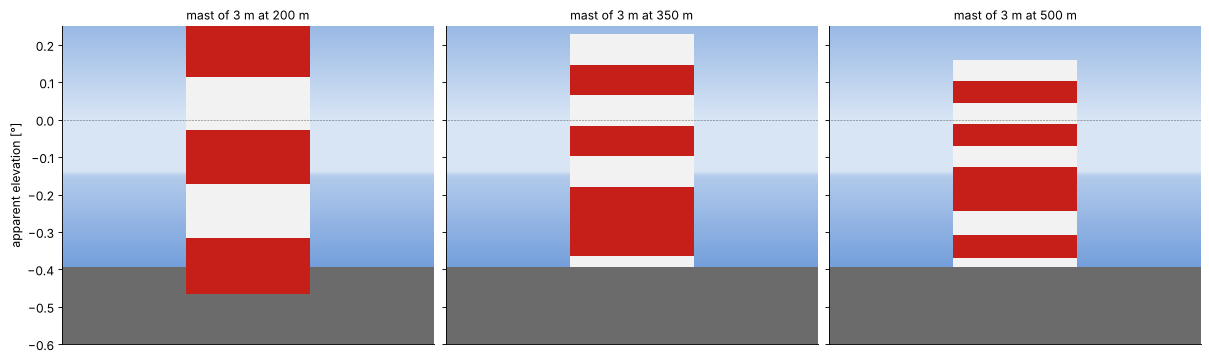

In [14]:
alpha_img = -np.linspace(-0.25, 0.60, 860)*DEG
fan_i = grin.trace(road, np.tile([0.0, y_eye], (len(alpha_img), 1)),
                   np.c_[np.cos(alpha_img), np.sin(alpha_img)], 0.5,
                   stop=lambda r: np.minimum(r[:, 1], 650.0 - r[:, 0]))


def mast_colour(y):
    stripe = (np.floor(y/0.5) % 2 == 0)
    return np.where(stripe[:, None], [0.78, 0.12, 0.1], [0.95, 0.95, 0.95])


def sky_colour(elev):
    t = np.clip(elev/(0.4*DEG), 0, 1)[:, None]
    return (1 - t)*np.array([0.85, 0.9, 0.96]) + t*np.array([0.45, 0.62, 0.86])


fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True, layout="constrained")
for ax, D in zip(axes, (200.0, 350.0, 500.0)):
    cols = np.zeros((len(alpha_img), 3))
    for j in range(len(alpha_img)):
        p = fan_i.path[:, j]
        reached = p[-1, 0] >= D
        if reached:
            y_D = np.interp(D, p[:, 0], p[:, 1])
            cols[j] = mast_colour(np.array([y_D]))[0] if y_D <= 3.0 else np.nan
        if not reached or np.isnan(cols[j, 0]):
            if fan_i.position[j, 1] < 1e-6:
                cols[j] = [0.42, 0.42, 0.42]                     # road
            else:
                el = np.arctan2(fan_i.direction[j, 1], fan_i.direction[j, 0])
                cols[j] = sky_colour(np.array([el]))[0]
    # the mast is 0.3 m wide: columns with and without it
    width = 8
    img_mast = np.repeat(cols[:, None, :], width, axis=1)
    img_bg = img_mast.copy()
    for j in range(len(alpha_img)):
        if fan_i.position[j, 1] < 1e-6:
            img_bg[j] = [0.42, 0.42, 0.42]
        else:
            el = np.arctan2(fan_i.direction[j, 1], fan_i.direction[j, 0])
            img_bg[j] = sky_colour(np.array([el]))[0]
    picture = np.concatenate([img_bg, img_mast, img_bg], axis=1)
    ax.imshow(picture, extent=(0, 3, alpha_img[-1]/DEG, alpha_img[0]/DEG), aspect="auto",
              origin="upper", interpolation="nearest")
    ax.axhline(0, color="k", lw=0.5, ls=":")
    ax.set_xticks([]); ax.set_title(f"mast of 3 m at {D:.0f} m", fontsize=11)
axes[0].set_ylabel("apparent elevation [°]")

At 200 m the mast stands on the road with a short mirrored foot
underneath and a strip of "water" (mirrored sky) around it. At 350 m and
500 m its lower part is gone, swallowed by the bright band of mirrored sky,
and an inverted copy of the stripes hangs below; the dotted line is the
horizon. (The angles are tiny: the whole picture spans less than a degree,
about two Moon diameters.)

### Waves at the turning point

Rays turn smoothly; waves do something more: the incident and the
returning light interfere, and at the turning height, a caustic, the
field does not diverge but has an Airy-type maximum, with evanescent light
below. For a real road this happens on micrometre scales over hundreds of
metres, far too large for a wave solver, so the profile is scaled:
$\lambda$ = 1, $h$ = 3, $\delta$ = 0.45, a beam at 0.5 rad.

First a Gaussian beam, launched by a line of `PointSource`s with a linear
phase, next to its rays (FDFD, 16 cells per λ):

FDFD (368640 unknowns): 5 s


Text(0.5, 1.0, 'a beam turned by the hot layer: |Ez|² (FDFD), rays, and the turning height (dashed)')

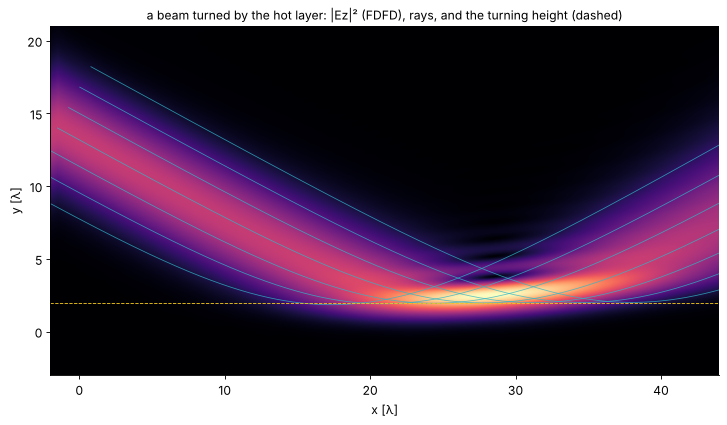

In [15]:
mir = grin.ExponentialLayer(1.0, 0.45, 3.0)
eps_m = lambda X, Y: np.maximum(mir.n2(np.stack([X, Y], axis=-1)), 0.1)
alpha_b, y_b, w_b, x_b = 0.5, 14.0, 4.0, -1.5
sim_m = GradedSimulation(fdtd.Grid((48.0, 30.0), 1/16, center=(21.0, 7.0)), eps_m)
xm, ym = sim_m.coords("Ez")
ky = -k0*mir.n(np.array([0.0, y_b]))*np.sin(alpha_b)
sources = [fdfd.PointSource((x_b, yy), np.exp(-(yy - y_b)**2/w_b**2)*np.exp(1j*ky*yy))
           for yy in ym[np.abs(ym - y_b) < 3*w_b]]
t0 = time.time()
sol_m = sim_m.solve(1.0, sources)
print("FDFD ({} unknowns): {:.0f} s".format(np.prod(sim_m.grid.shape), time.time() - t0))
offs = np.linspace(-1.2, 1.2, 7)*w_b
starts = np.c_[x_b + offs*np.sin(alpha_b), y_b + offs*np.cos(alpha_b)]
rays_m = grin.trace(mir, starts, np.tile([np.cos(alpha_b), -np.sin(alpha_b)], (len(offs), 1)), 0.05,
                    stop=lambda r: r[:, 0] - 44.0)
fig, ax = plt.subplots(figsize=(14, 5.2), layout="constrained")
show_intensity(ax, np.abs(sol_m.main)**2, xm, ym, gamma=0.5)
ax.plot(rays_m.path[:, :, 0], rays_m.path[:, :, 1], color=RAY, lw=0.7, alpha=0.8)
beta_b = mir.n(np.array([0.0, y_b]))*np.cos(alpha_b)
ax.axhline(mir.turning_height(beta_b), color=EXACT, lw=0.8, ls="--")
ax.set_xlim(-2, 44); ax.set_ylim(-3, 21); ax.set_aspect("equal")
ax.set_xlabel("x [λ]"); ax.set_ylabel("y [λ]")
ax.set_title("a beam turned by the hot layer: |Ez|² (FDFD), rays, and the turning height (dashed)",
             fontsize=11)

The beam turns where its rays do. Above the turning height the
down- and up-going parts overlap only in a short triangle, so the fringes
are faint. The exact wave picture is cleaner with a plane wave of a single
angle: $u = f(y)\,e^{i\beta k_0x}$ with
$f'' + k_0^2(c - \delta e^{-y/h})f = 0$, $c = n_\infty^2 - \beta^2$. The
substitution $s = 2hk_0\sqrt\delta\,e^{-y/(2h)}$ turns this into the
modified Bessel equation of imaginary order $i\mu$, $\mu = 2hk_0\sqrt c$, and
the solution that decays into the ground is
$$f(y) = K_{i\mu}\!\left(2hk_0\sqrt\delta\,e^{-y/(2h)}\right),$$
real valued (computed with `mpmath`). Near the turning point the profile is
nearly linear, and $f$ approaches the Airy function
$\mathrm{Ai}(-(y - y_t)/\ell)$ with $\ell = (k_0^2\,\mathrm dn^2/\mathrm dy)^{-1/3}$,
as for a rainbow (notebook 71).

To get a plane wave in the FDFD, the cell is one wavelength wide with a
Bloch boundary $e^{i\beta k_0L}$ in $x$, and a horizontal line of sources
with the phase $e^{i\beta k_0x}$ emits plane waves up (into the PML) and
down; the downward wave comes back from the hot layer, and below the
sources the field is a pure standing wave $f(y)$.

alpha = 0.5: rms deviation FDFD - K_imu below the source 0.97 %
alpha = 0.3: rms deviation FDFD - K_imu below the source 0.19 %


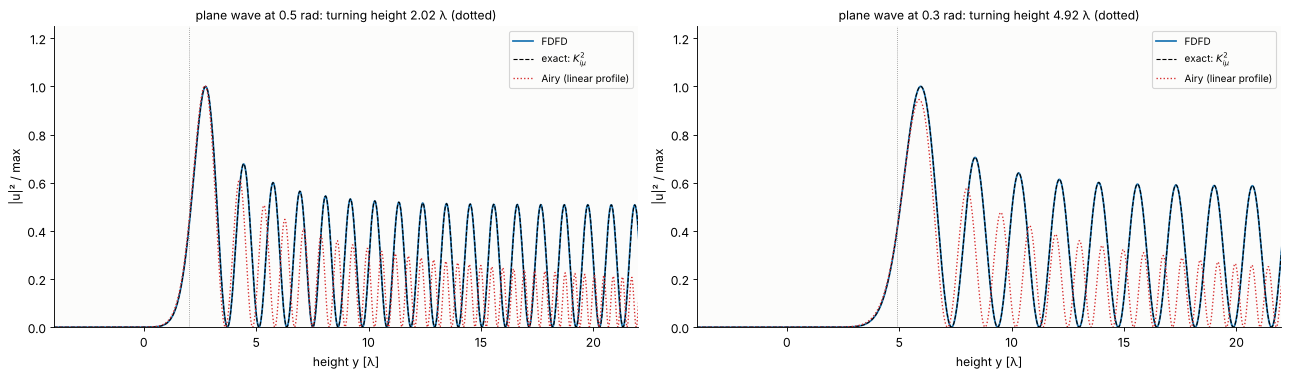

In [16]:
h_b = 1/32
grid_p = fdtd.Grid((1.0, 46.0), h_b, center=(0.0, 10.0))
xp_nodes = np.arange(grid_p.shape[0])*h_b + grid_p.origin[0]
y_src = 26.0
res_p = {}
for alpha_p in (0.5, 0.3):
    beta_p = np.cos(alpha_p)
    # Bloch wave number whose discrete second difference equals (beta k0)^2
    kx = 2/h_b*np.arcsin(beta_p*k0*h_b/2)
    sim_p = GradedSimulation(grid_p, eps_m, boundaries=(fdtd.boundaries.Bloch(kx), fdtd.boundaries.PML(32)))
    src_p = [fdfd.PointSource((xx, y_src), np.exp(1j*kx*xx)) for xx in xp_nodes]
    sol_p = sim_p.solve(1.0, src_p)
    yp = sol_p.coords["Ez"][1]
    f_fd = sol_p.main[0]*np.exp(-1j*kx*xp_nodes[0])
    mu = 2*mir.h*k0*np.sqrt(1 - beta_p**2)
    s = 2*mir.h*k0*np.sqrt(mir.delta)*np.exp(-yp/(2*mir.h))
    f_ex = np.array([float(mpmath.besselk(1j*mu, si).real) for si in s])
    y_t = mir.turning_height(beta_p)
    ell = (k0**2*(1 - beta_p**2)/mir.h)**(-1/3)     # dn^2/dy = c/h at the turning point
    f_ai = airy(-(yp - y_t)/ell)[0]
    res_p[alpha_p] = (yp, f_fd, f_ex, f_ai, y_t)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), layout="constrained")
for ax, (alpha_p, (yp, f_fd, f_ex, f_ai, y_t)) in zip(axes, res_p.items()):
    below = (yp > -6) & (yp < y_src - 2)
    # match the complex amplitude by least squares, below the sources
    a_ex = np.vdot(f_ex[below], f_fd[below])/np.vdot(f_ex[below], f_ex[below])
    a_ai = np.vdot(f_ai[below & (yp < y_t + 3)], f_fd[below & (yp < y_t + 3)]) / \
        np.vdot(f_ai[below & (yp < y_t + 3)], f_ai[below & (yp < y_t + 3)])
    rel = np.linalg.norm((f_fd - a_ex*f_ex)[below])/np.linalg.norm(f_fd[below])
    nrm = np.max(f_ex[below]**2)
    ax.plot(yp, np.abs(f_fd)**2/np.abs(a_ex)**2/nrm, color="C0", lw=1.6, label="FDFD")
    ax.plot(yp, f_ex**2/nrm, "k--", lw=1, label=r"exact: $K_{i\mu}^2$")
    ax.plot(yp, np.abs(a_ai*f_ai)**2/np.abs(a_ex)**2/nrm, ":", color="C3", lw=1.2, label="Airy (linear profile)")
    ax.axvline(y_t, color="0.5", lw=0.7, ls=":")
    ax.set_xlim(-4, 22); ax.set_ylim(0, 1.25); ax.set_xlabel("height y [λ]"); ax.set_ylabel("|u|² / max")
    ax.legend(fontsize=9, loc="upper right")
    ax.set_title(f"plane wave at {alpha_p} rad: turning height {y_t:.2f} λ (dotted)", fontsize=11)
    print(f"alpha = {alpha_p}: rms deviation FDFD - K_imu below the source {100*rel:.2f} %")

The FDFD standing wave is the Bessel function of imaginary order within
1 % rms: a main maximum just above the turning height,
fringes above it with the spacing $\lambda/(2\sin\alpha)$ of two crossing
plane waves, and an exponential decay into the "forbidden" layer below.
The Airy function of the linearized profile fits the first fringes; further
up the exponential profile flattens and the Airy fringes run ahead. In the
eye the fringes are washed out by the bandwidth of daylight and the
turbulence of the hot air (notebook 72), which also makes the "water"
shimmer; what is left is the geometric optics of the rays.

## Summary

- `grin.trace()` integrates the ray equation $\ddot{\mathbf r} = \tfrac12\nabla n^2$
  with Sharma's Runge-Kutta-Nyström scheme (fourth order, verified on the
  parabolic rod), with the optical path, for many rays at once, ending
  rays exactly on a surface.
- **GRIN rods:** the parabolic rod has the pitch $P_0\cos\theta$, a
  spherical aberration that blurs the image of a point along the axis
  (WPM: the focus moves forward and loses half its peak); the
  $\mathrm{sech}$ profile has the same pitch $2\pi/g$ for every meridional ray
  and images sharply, inverted at $P/2$ and upright at $P$.
- **Luneburg lens:** rays are ellipses about the centre, every parallel
  bundle meets on the opposite surface at $t = \pi R/2$ with equal optical
  paths; the FDFD focus sits at the surface and is diffraction limited for
  every direction.
- **Maxwell's fish-eye:** traced rays lie on circles through
  $\mathbf r_0$ and $-\mathbf r_0R^2/|\mathbf r_0|^2$, all with the optical
  path $\pi R$; in Leonhardt's mirror the FDFD field matches the exact
  Legendre Green's function (6 % rms), the image is a diffraction limited spot, and
  the resonances are $\ell$-fold degenerate at $k_0R = \sqrt{\ell(\ell + 1)}$.
- **Mirage:** with real temperatures, rays within 0.39° below the horizon
  are bent back by the hot air; the traced heights match the closed form
  of the exponential profile, each object point is seen upright and
  inverted, and the base of far objects vanishes behind mirrored sky. At
  the turning height waves form the Bessel function $K_{i\mu}$ (FDFD within
  1 %), close to an Airy function.

## References

- A. Sharma, D. V. Kumar and A. K. Ghatak, "Tracing rays through graded-index media: a new method", Appl. Opt. 21, 984-987 (1982).
- E. W. Marchand, *Gradient Index Optics*, Academic Press (1978).
- A. L. Mikaelian, "Self-focusing media with variable index of refraction", Progress in Optics 17, 279-345 (1980).
- C. Gomez-Reino, M. V. Perez and C. Bao, *Gradient-Index Optics: Fundamentals and Applications*, Springer (2002).
- R. K. Luneburg, *Mathematical Theory of Optics*, University of California Press (1964).
- J. C. Maxwell, "Solutions of problems", Cambridge and Dublin Math. J. 8, 188-195 (1854).
- U. Leonhardt, "Perfect imaging without negative refraction", New J. Phys. 11, 093040 (2009).
- R. J. Blaikie, "Comment on 'Perfect imaging without negative refraction'", New J. Phys. 12, 058001 (2010); U. Leonhardt, "Reply to comment", New J. Phys. 12, 058002 (2010).
- R. Merlin, "Maxwell's fish-eye lens and the mirage of perfect imaging", J. Opt. 13, 024017 (2011).
- U. Leonhardt and T. G. Philbin, *Geometry and Light: The Science of Invisibility*, Dover (2010), chapter 5.
- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge University Press (1999), sections 3.2 and 4.2.
- P. E. Ciddor, "Refractive index of air: new equations for the visible and near infrared", Appl. Opt. 35, 1566-1573 (1996).
- A. T. Young, "An introduction to mirages", https://aty.sdsu.edu/mirages/mirintro.html.
- K.-H. Brenner and W. Singer, "Light propagation through microlenses: a new simulation method", Appl. Opt. 32, 4984-4988 (1993).
- NIST Digital Library of Mathematical Functions, sections 10.45 (modified Bessel functions of imaginary order) and 14.3 (Legendre functions), https://dlmf.nist.gov.

In [17]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 65 s
